# Benchmark Hiệu Năng Phân Loại Zero-Shot CLIP Với Các Kỹ Thuật Tiền Xử Lý & Tăng Cường Dữ Liệu

Notebook này đánh giá hiệu năng phân loại vật nuôi (37 giống chó mèo từ tập dữ liệu **Oxford-IIIT Pet**) sử dụng mô hình **CLIP Zero-Shot (`openai/clip-vit-base-patch32`)**.

Chúng ta thực hiện benchmark hiệu năng của các cấu hình tiền xử lý ảnh trên:
1. **Tập Validation của phân chia trainval** ở các tỉ lệ stratified splits khác nhau (`6:4`, `7:3`, `8:2`, `9:1`).
2. **Tập Test độc lập đầy đủ (100% test set - 3,669 mẫu ảnh)**.

Các phương pháp xử lý ảnh bao gồm:
- **Baseline:** Ảnh gốc chuẩn hóa qua CLIP processor.
- **Bilateral Denoise:** Lọc giảm nhiễu song phương giúp mịn da/lông vật nuôi và bảo toàn biên cạnh.
- **CLAHE (LAB):** Tăng cường độ tương phản thích ứng cục bộ trên kênh L (không gian màu LAB).
- **Bilateral + CLAHE:** Kết hợp lọc giảm nhiễu song phương và cân bằng độ sáng thích ứng CLAHE.
- **Bilateral + CLAHE + Geom:** Áp dụng tiền xử lý kèm thêm tăng cường hình học (lật ngang, xoay ngẫu nhiên).
- **Test-Time Augmentation (TTA):** Tích hợp đặc trưng trung bình từ 5 views ảnh ở trên.

## 1. Thiết lập môi trường và nạp dữ liệu

In [1]:
import os
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL.Image
from PIL import Image
from tqdm import tqdm
from torchvision.datasets import OxfordIIITPet
from transformers import CLIPModel, CLIPProcessor
from torch.utils.data import DataLoader, Dataset

def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(0)
device = torch.device("mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu"))
print("Thiết bị sử dụng:", device)

# Tự động phát hiện thư mục chứa dataset
dataset_root = "../dataset"
for path in ["../dataset", "dataset", ".", "../../dataset", "../../../dataset"]:
    if os.path.exists(os.path.join(path, "oxford-iiit-pet")):
        dataset_root = path
        break

print(f"Thư mục dữ liệu: {os.path.abspath(dataset_root)}")
pets_trainval = OxfordIIITPet(root=dataset_root, download=False, split="trainval")
pets_test = OxfordIIITPet(root=dataset_root, download=False, split="test")
class_names = pets_trainval.classes

print(f"Số lượng ảnh trainval: {len(pets_trainval)}")
print(f"Số lượng ảnh test: {len(pets_test)}")
print(f"Số lượng giống loài (classes): {len(class_names)}")

Thiết bị sử dụng: mps
Thư mục dữ liệu: /Users/nguyenhuuhoangluan/Git_Code/CLIP-Animal-Classifier/dataset
Số lượng ảnh trainval: 3680
Số lượng ảnh test: 3669
Số lượng giống loài (classes): 37


## 2. Định nghĩa các hàm xử lý ảnh và Dataset Wrapper

In [2]:
def apply_denoise(pil_img):
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    denoised = cv2.bilateralFilter(img_bgr, d=9, sigmaColor=75, sigmaSpace=75)
    return Image.fromarray(cv2.cvtColor(denoised, cv2.COLOR_BGR2RGB))

def apply_clahe(pil_img):
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    clahe_bgr = cv2.cvtColor(cv2.merge((cl,a,b)), cv2.COLOR_LAB2BGR)
    return Image.fromarray(cv2.cvtColor(clahe_bgr, cv2.COLOR_BGR2RGB))

def full_preprocess(pil_img):
    img_np = np.array(pil_img)
    img_bgr = cv2.cvtColor(img_np, cv2.COLOR_RGB2BGR)
    denoised = cv2.bilateralFilter(img_bgr, d=9, sigmaColor=75, sigmaSpace=75)
    lab = cv2.cvtColor(denoised, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
    cl = clahe.apply(l)
    processed_bgr = cv2.cvtColor(cv2.merge((cl,a,b)), cv2.COLOR_LAB2BGR)
    return Image.fromarray(cv2.cvtColor(processed_bgr, cv2.COLOR_BGR2RGB))

class TransformedDataset(Dataset):
    def __init__(self, base_dataset, transform_fn, clip_processor):
        self.base_dataset = base_dataset
        self.transform_fn = transform_fn
        self.clip_processor = clip_processor
        
    def __len__(self):
        return len(self.base_dataset)
        
    def __getitem__(self, idx):
        img, label = self.base_dataset[idx]
        if self.transform_fn is not None:
            img = self.transform_fn(img)
        pixel_values = self.clip_processor(images=img, return_tensors="pt")["pixel_values"][0]
        return pixel_values, label

## 3. Trực quan hóa ảnh qua từng bước xử lý kèm theo Histogram tương ứng

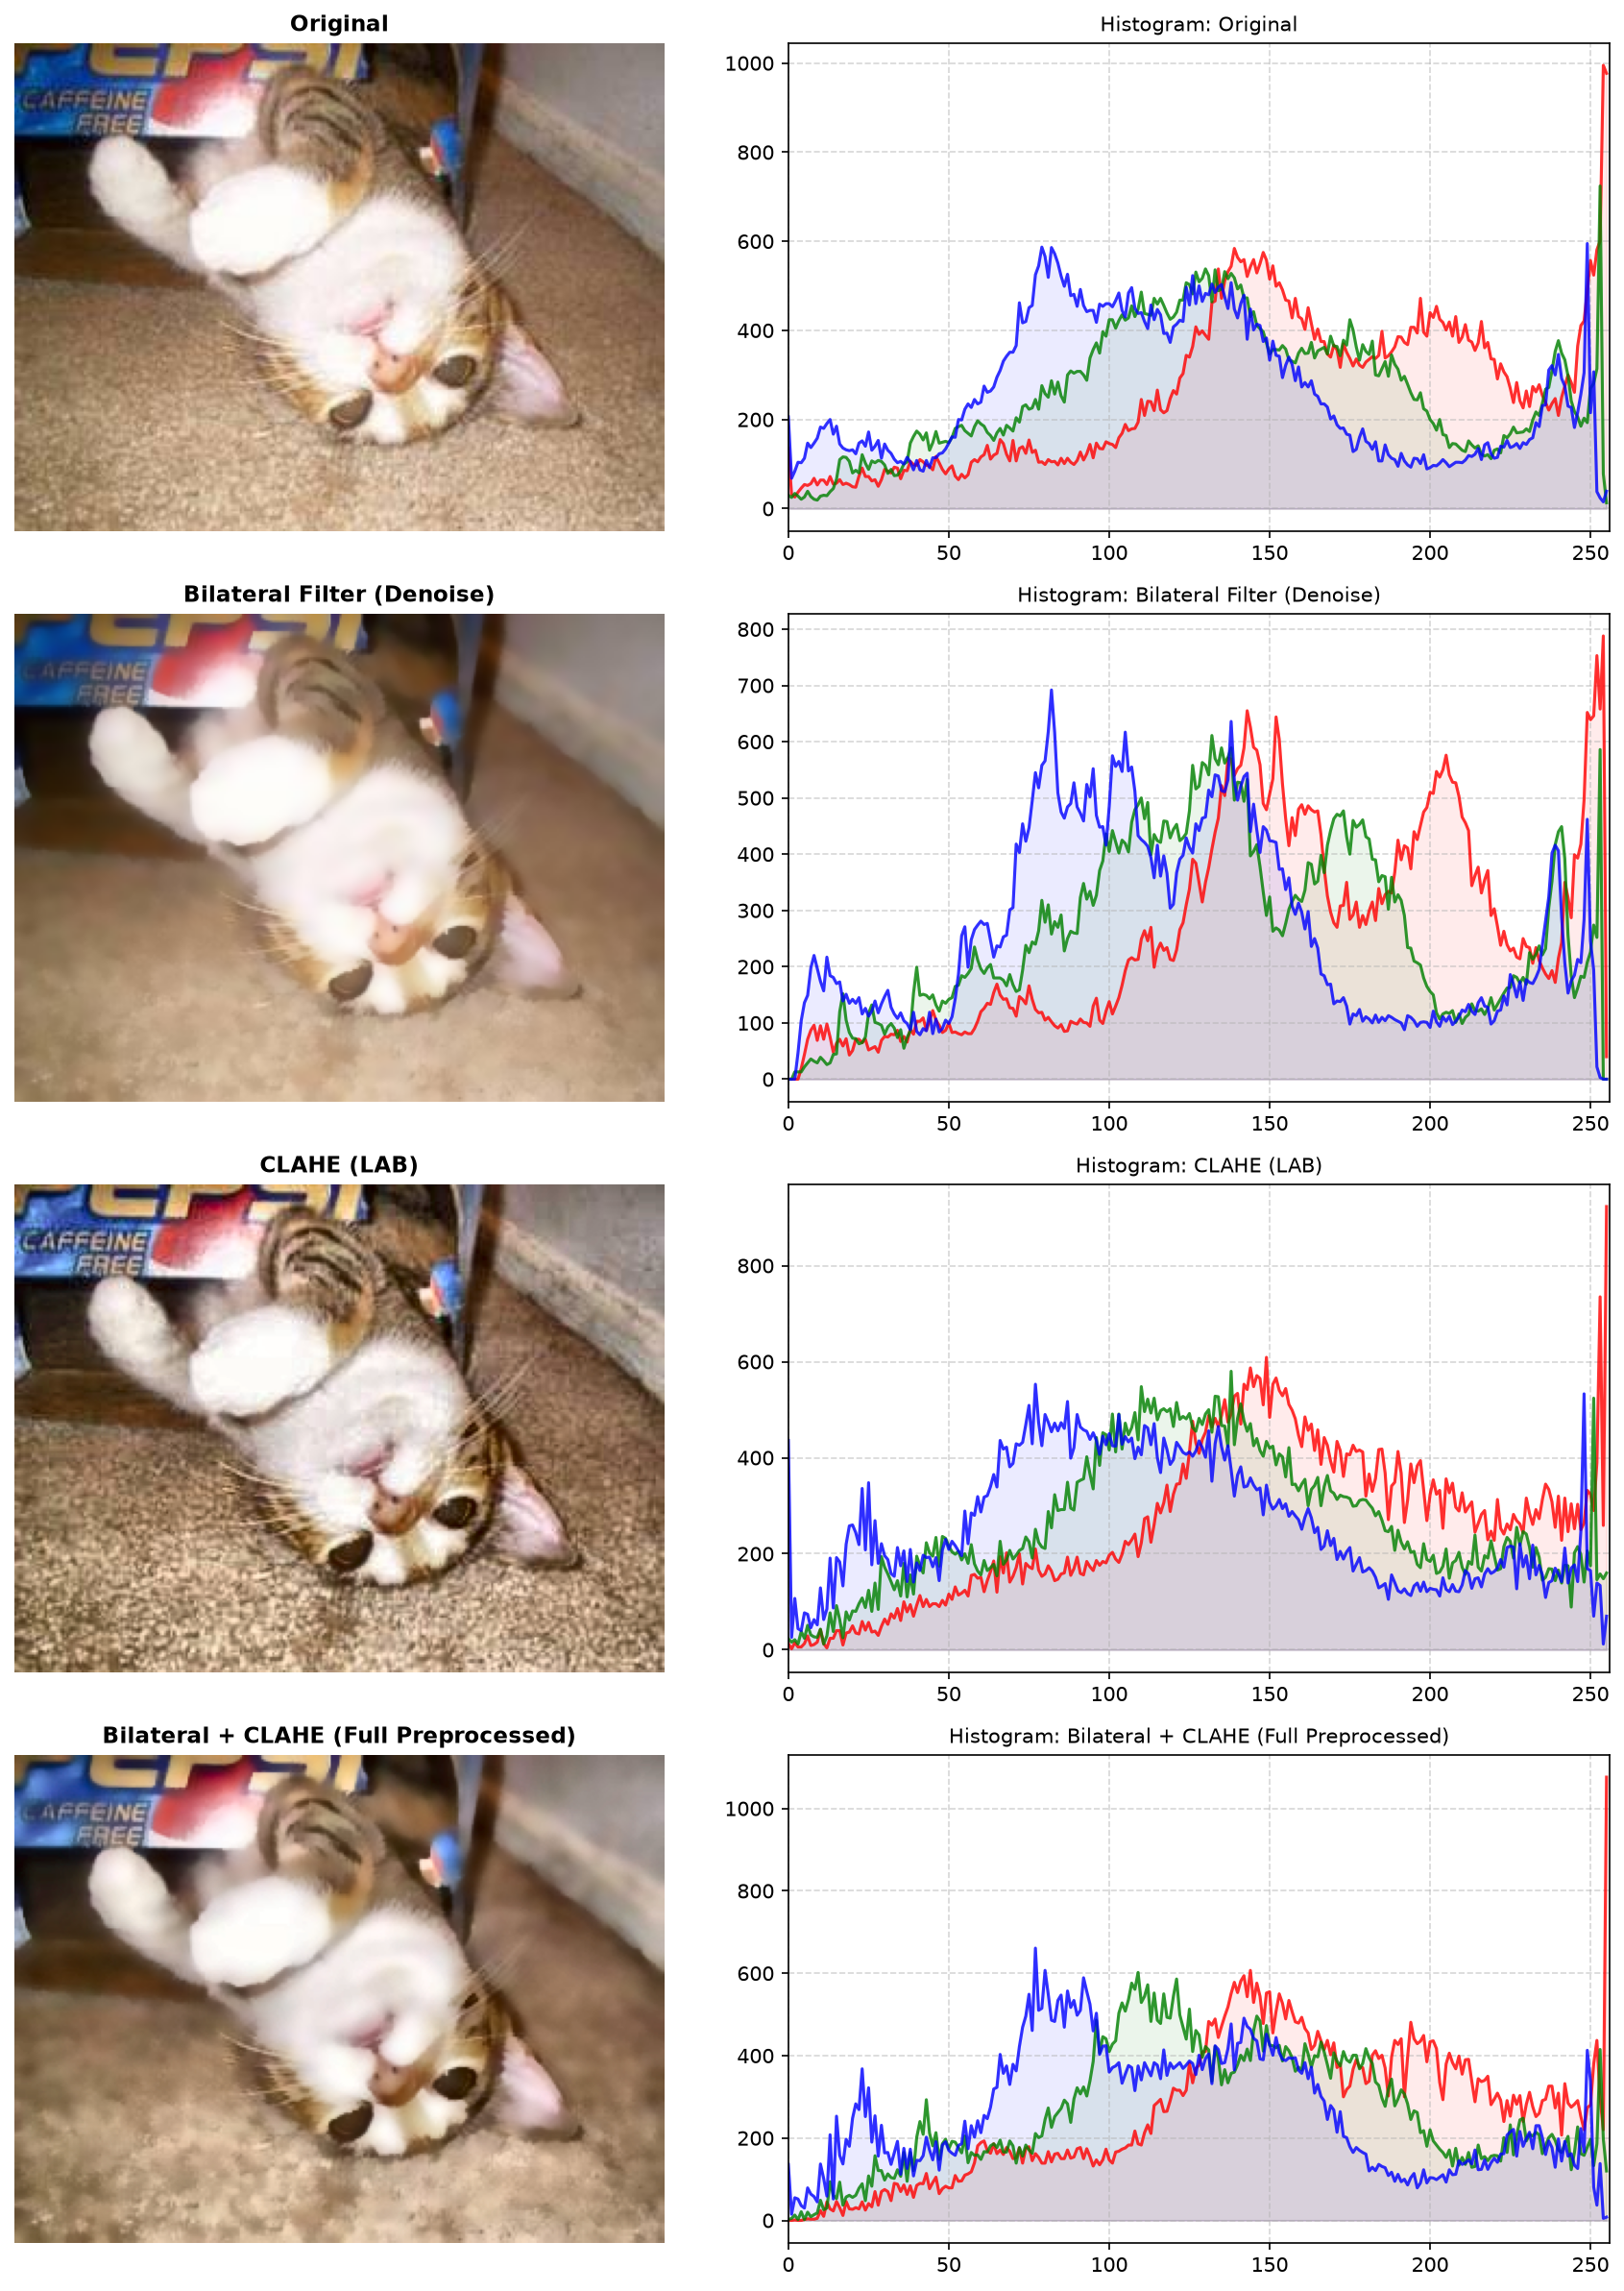

In [3]:
sample_img, _ = pets_test[10]
img_denoised = apply_denoise(sample_img)
img_clahe = apply_clahe(sample_img)
img_processed = full_preprocess(sample_img)

images_list = [
    ("Original", sample_img),
    ("Bilateral Filter (Denoise)", img_denoised),
    ("CLAHE (LAB)", img_clahe),
    ("Bilateral + CLAHE (Full Preprocessed)", img_processed)
]

fig, axes = plt.subplots(4, 2, figsize=(12, 16), dpi=150)

for idx, (title, img) in enumerate(images_list):
    axes[idx, 0].imshow(img)
    axes[idx, 0].set_title(title, fontsize=11, fontweight='bold')
    axes[idx, 0].axis('off')
    
    img_np = np.array(img)
    colors = ('red', 'green', 'blue')
    for i, col in enumerate(colors):
        hist = cv2.calcHist([img_np], [i], None, [256], [0, 256]).flatten()
        axes[idx, 1].plot(hist, color=col, alpha=0.8, linewidth=1.5)
        axes[idx, 1].fill_between(range(256), hist, color=col, alpha=0.08)
    axes[idx, 1].set_xlim([0, 256])
    axes[idx, 1].set_title(f"Histogram: {title}", fontsize=10)
    axes[idx, 1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 4. Nạp mô hình CLIP và chuẩn bị đặc trưng văn bản nhãn thô

In [4]:
print("Nạp mô hình CLIP Vit-B/32...")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device)
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model.eval()

with torch.no_grad():
    inputs = processor(text=[c for c in class_names], return_tensors="pt", padding=True).to(device)
    text_features = model.get_text_features(**inputs)
    text_features = text_features / text_features.norm(dim=-1, keepdim=True)
print("Kích thước đặc trưng văn bản nhãn thô:", text_features.shape)

Nạp mô hình CLIP Vit-B/32...


Kích thước đặc trưng văn bản nhãn thô: torch.Size([37, 512])


## 5. Trích xuất đặc trưng hình ảnh cho cả tập Trainval và tập Test

In [5]:
def extract_features(dataset, desc=""):
    loader = DataLoader(dataset, batch_size=128, shuffle=False, num_workers=0)
    features_list = []
    labels_list = []
    with torch.no_grad():
        for batch_pixels, batch_labels in tqdm(loader, desc=desc):
            batch_pixels = batch_pixels.to(device)
            img_feats = model.get_image_features(pixel_values=batch_pixels)
            img_feats = img_feats / img_feats.norm(dim=-1, keepdim=True)
            features_list.append(img_feats.cpu())
            labels_list.append(batch_labels)
    return torch.cat(features_list, dim=0), torch.cat(labels_list, dim=0)

print("--- TRÍCH XUẤT ĐẶC TRƯNG TẬP TRAINVAL ---")
trainval_feats_dict = {}
trainval_feats_dict["Baseline"], trainval_labels = extract_features(TransformedDataset(pets_trainval, None, processor), "Trainval Baseline")
trainval_feats_dict["Bilateral_Denoise"], _ = extract_features(TransformedDataset(pets_trainval, apply_denoise, processor), "Trainval Denoise")
trainval_feats_dict["CLAHE"], _ = extract_features(TransformedDataset(pets_trainval, apply_clahe, processor), "Trainval CLAHE")
trainval_feats_dict["Bilateral_CLAHE"], _ = extract_features(TransformedDataset(pets_trainval, full_preprocess, processor), "Trainval Bilateral+CLAHE")

transform_geom = lambda img: full_preprocess(img).transpose(PIL.Image.FLIP_LEFT_RIGHT).rotate(15)
trainval_feats_dict["Bilateral_CLAHE_Geom"], _ = extract_features(TransformedDataset(pets_trainval, transform_geom, processor), "Trainval Geom")

# Trainval TTA
all_trainval_feats = [trainval_feats_dict[k] for k in ["Baseline", "Bilateral_Denoise", "CLAHE", "Bilateral_CLAHE", "Bilateral_CLAHE_Geom"]]
feats_trainval_tta = torch.stack(all_trainval_feats, dim=0).mean(dim=0)
feats_trainval_tta = feats_trainval_tta / feats_trainval_tta.norm(dim=-1, keepdim=True)
trainval_feats_dict["TTA"] = feats_trainval_tta

print("\n--- TRÍCH XUẤT ĐẶC TRƯNG TẬP TEST ---")
test_feats_dict = {}
test_feats_dict["Baseline"], test_labels = extract_features(TransformedDataset(pets_test, None, processor), "Test Baseline")
test_feats_dict["Bilateral_Denoise"], _ = extract_features(TransformedDataset(pets_test, apply_denoise, processor), "Test Denoise")
test_feats_dict["CLAHE"], _ = extract_features(TransformedDataset(pets_test, apply_clahe, processor), "Test CLAHE")
test_feats_dict["Bilateral_CLAHE"], _ = extract_features(TransformedDataset(pets_test, full_preprocess, processor), "Test Bilateral+CLAHE")
test_feats_dict["Bilateral_CLAHE_Geom"], _ = extract_features(TransformedDataset(pets_test, transform_geom, processor), "Test Geom")

# Test TTA
all_test_feats = [test_feats_dict[k] for k in ["Baseline", "Bilateral_Denoise", "CLAHE", "Bilateral_CLAHE", "Bilateral_CLAHE_Geom"]]
feats_test_tta = torch.stack(all_test_feats, dim=0).mean(dim=0)
feats_test_tta = feats_test_tta / feats_test_tta.norm(dim=-1, keepdim=True)
test_feats_dict["TTA"] = feats_test_tta

--- TRÍCH XUẤT ĐẶC TRƯNG TẬP TRAINVAL ---


Trainval Baseline:   0%|          | 0/29 [00:00<?, ?it/s]

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Trainval Baseline:   3%|▎         | 1/29 [00:00<00:21,  1.31it/s]

Trainval Baseline:   7%|▋         | 2/29 [00:01<00:19,  1.39it/s]

Trainval Baseline:  10%|█         | 3/29 [00:02<00:18,  1.42it/s]

... (303 outputs left out)

Test Geom:  93%|█████████▎| 27/29 [00:27<00:02,  1.02s/it]

Test Geom:  97%|█████████▋| 28/29 [00:28<00:01,  1.04s/it]

Test Geom: 100%|██████████| 29/29 [00:29<00:00,  1.06it/s]

Test Geom: 100%|██████████| 29/29 [00:29<00:00,  1.02s/it]

## 6. Hiện thực quy trình Stratified Split và Đánh Giá Hiệu Năng

In [6]:
def get_train_val_split_indices(labels, train_ratio=0.9, seed=0):
    set_seed(seed)
    num_classes = 37
    train_idx = []
    val_idx = []
    
    for c in range(num_classes):
        class_indices = (labels == c).nonzero(as_tuple=True)[0]
        shuffled = class_indices[torch.randperm(len(class_indices))]
        
        split_point = int(len(class_indices) * train_ratio)
        train_idx.append(shuffled[:split_point])
        val_idx.append(shuffled[split_point:])
        
    train_idx = torch.cat(train_idx)
    val_idx = torch.cat(val_idx)
    return train_idx, val_idx

def evaluate_acc(img_feats, lbls, text_feats, val_idx=None):
    if val_idx is not None:
        feats = img_feats[val_idx].to(device)
        labels_to_eval = lbls[val_idx].to(device)
    else:
        feats = img_feats.to(device)
        labels_to_eval = lbls.to(device)
    sim = feats @ text_feats.t()
    preds = sim.argmax(dim=-1)
    return (preds == labels_to_eval).float().mean().item() * 100

ratios = {"6:4": 0.6, "7:3": 0.7, "8:2": 0.8, "9:1": 0.9}
methods = ["Baseline", "Bilateral_Denoise", "CLAHE", "Bilateral_CLAHE", "Bilateral_CLAHE_Geom", "TTA"]
results = {}

# Đánh giá trên các tỉ lệ split của tập Trainval
for r_name, r_val in ratios.items():
    _, val_idx = get_train_val_split_indices(trainval_labels, train_ratio=r_val, seed=0)
    results[r_name] = {}
    for m in methods:
        acc = evaluate_acc(trainval_feats_dict[m], trainval_labels, text_features, val_idx)
        results[r_name][m] = acc

# Đánh giá trên toàn bộ tập Test độc lập (100%)
results["Full Test Set (100%)"] = {}
for m in methods:
    acc = evaluate_acc(test_feats_dict[m], test_labels, text_features, None)
    results["Full Test Set (100%)"][m] = acc

df = pd.DataFrame(results).T
df.index.name = "Split"

print("\n--- Bảng kết quả Accuracy (%) ---")
print(df.to_string(formatters={c: '{:,.2f}%'.format for c in df.columns}))

delta_df = df.copy()
for col in delta_df.columns:
    if col != "Baseline":
        delta_df[col] = delta_df[col] - delta_df["Baseline"]
delta_df["Baseline"] = 0.0

print("\n--- Bảng thay đổi Accuracy so với Baseline (Delta Accuracy) ---")
print(delta_df.to_string(formatters={c: '{:+,.2f}%'.format for c in delta_df.columns}))


--- Bảng kết quả Accuracy (%) ---
                     Baseline Bilateral_Denoise  CLAHE Bilateral_CLAHE Bilateral_CLAHE_Geom    TTA
Split                                                                                             
6:4                    75.12%            74.17% 75.39%          73.08%               72.34% 76.41%
7:3                    75.29%            73.94% 75.48%          73.03%               72.94% 76.47%
8:2                    75.64%            73.61% 75.51%          73.61%               73.48% 76.73%
9:1                    75.68%            72.97% 75.14%          72.43%               72.16% 76.49%
Full Test Set (100%)   80.16%            78.71% 78.74%          78.14%               75.74% 80.65%

--- Bảng thay đổi Accuracy so với Baseline (Delta Accuracy) ---
                     Baseline Bilateral_Denoise  CLAHE Bilateral_CLAHE Bilateral_CLAHE_Geom    TTA
Split                                                                                             
6:4      

## 7. Vẽ đồ thị so sánh hiệu năng của các phương pháp

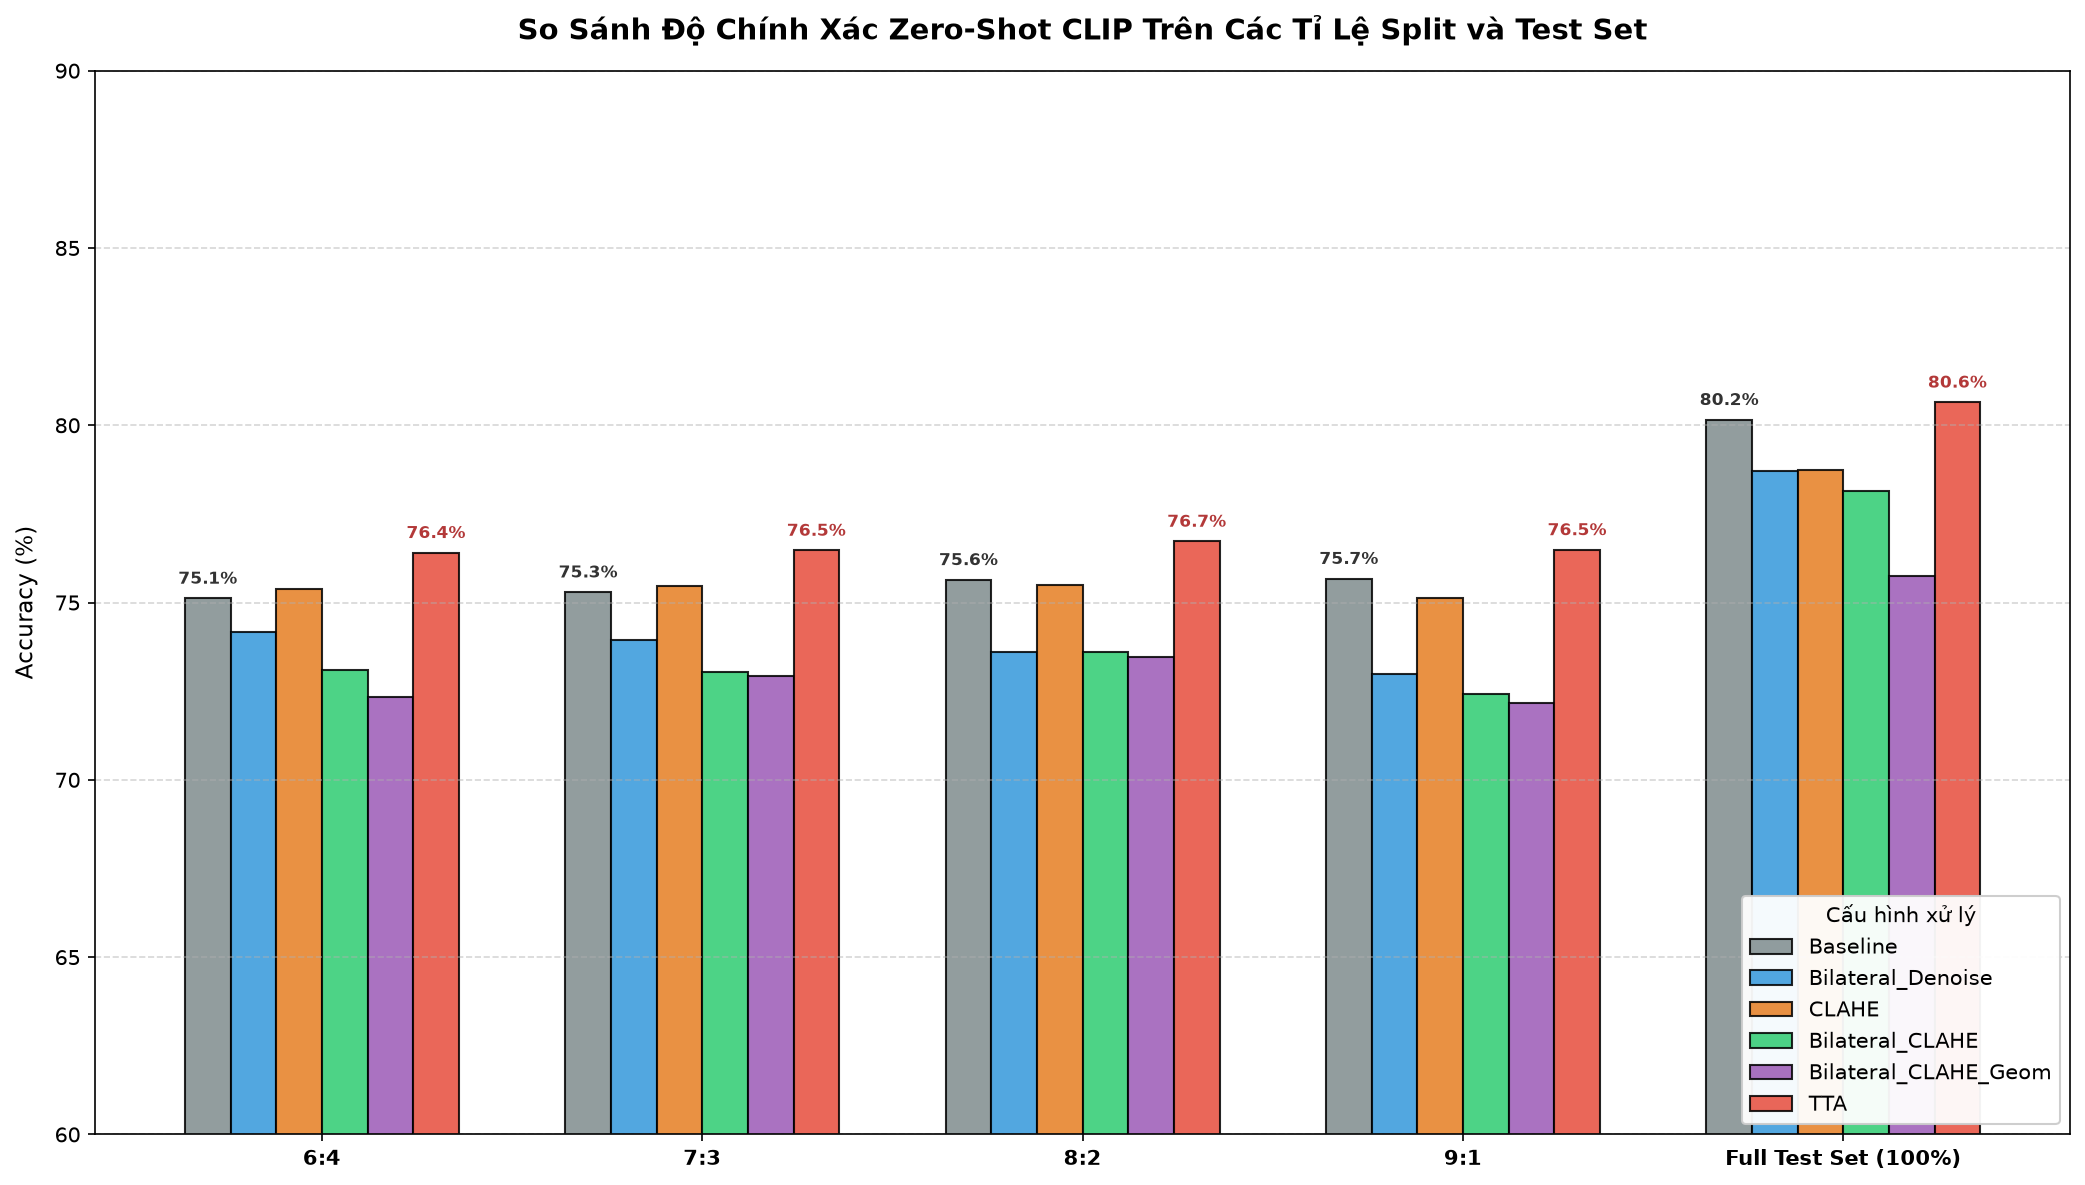

In [7]:
splits = list(df.index)
methods_plot = list(df.columns)
x = np.arange(len(splits))
width = 0.12

fig, ax = plt.subplots(figsize=(14, 8), dpi=150)
colors = ["#7f8c8d", "#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#e74c3c"]

for idx, m in enumerate(methods_plot):
    yvals = df[m].values
    ax.bar(x + (idx - 2.5) * width, yvals, width, label=m, color=colors[idx], edgecolor='black', alpha=0.85)

ax.set_title("So Sánh Độ Chính Xác Zero-Shot CLIP Trên Các Tỉ Lệ Split và Test Set", fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel("Accuracy (%)", fontsize=11, labelpad=8)
ax.set_xticks(x)
ax.set_xticklabels(splits, fontsize=10, fontweight='bold')
ax.set_ylim([60, 90])
ax.legend(title="Cấu hình xử lý", loc="lower right", framealpha=0.95)
ax.grid(True, linestyle="--", alpha=0.5, axis='y')

# Ghi giá trị số lên đầu các cột Baseline và TTA để trực quan hóa tốt hơn
for i in range(len(splits)):
    val_base = df.loc[splits[i], "Baseline"]
    ax.text(i - 2.5 * width, val_base + 0.3, f"{val_base:.1f}%", ha='center', va='bottom', fontsize=8, color="#333", fontweight='bold')
    val_tta = df.loc[splits[i], "TTA"]
    ax.text(i + 2.5 * width, val_tta + 0.3, f"{val_tta:.1f}%", ha='center', va='bottom', fontsize=8, color="#b33939", fontweight='bold')

plt.tight_layout()
plt.savefig("benchmark_comparison.png", dpi=300)
plt.show()